In [0]:
catalogo = "workspace"
esquema = "default"
tabla_netflix = f"{catalogo}.{esquema}.netflix_clean"
tabla_mr = f"{catalogo}.{esquema}.mapreduce_actores"

print("Catálogo:", catalogo)
print("Esquema:", esquema)
print("Tabla 1:", tabla_netflix)
print("Tabla 2:", tabla_mr)

ruta_netflix = "/Volumes/workspace/default/datasets/netflix_clean.csv"
netflix_clean = (
    spark.read
    .option("header", True)
    .option("quote", '"')
    .option("escape", '"')
    .option("multiLine", True)
    .schema("""
        show_id STRING, type STRING, title STRING, director STRING,
        cast STRING, country STRING, date_added STRING, release_year INT,
        rating STRING, duration STRING, listed_in STRING, description STRING,
        duration_min INT
    """)
    .csv(ruta_netflix)
)
netflix_clean.write.mode("overwrite").saveAsTable(tabla_netflix)
netflix_clean.createOrReplaceTempView("netflix_clean")
netflix_clean.show(5, truncate=False)
print("Total de registros en netflix_clean:", netflix_clean.count())

ruta_mr = "/Volumes/workspace/default/datasets/mapreduce_actores.csv"
mapreduce_actores = (
    spark.read
    .option("header", True)
    .option("quote", '"')
    .option("escape", '"')
    .schema("actor STRING, cantidad_titulos INT")
    .csv(ruta_mr)
)
mapreduce_actores.write.mode("overwrite").saveAsTable(tabla_mr)
mapreduce_actores.createOrReplaceTempView("mapreduce_actores")
mapreduce_actores.show(5, truncate=False)
print("Total de registros en mapreduce_actores:", mapreduce_actores.count())

Catálogo: workspace
Esquema: default
Tabla 1: workspace.default.netflix_clean
Tabla 2: workspace.default.mapreduce_actores
+-------+-------+---------------------+---------------+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-------------+----------+------------+------+---------+-------------------------------------------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------+------------+
|show_id|type   |title                |director       |cast                                                                                                                                                                               

In [0]:
# 1. Cabeceras interpretadas como nombres de columnas
print("Columnas netflix_clean:", netflix_clean.columns)
print("Columnas mapreduce_actores:", mapreduce_actores.columns)

# 2. Campos con comas leídos correctamente (sin desplazar columnas)
print("Muestra de registros con comas en cast:")
netflix_clean.select("show_id", "title", "cast", "release_year", "duration_min") \
    .filter("cast LIKE '%,%'") \
    .show(5, truncate=False)

# 3. Coincidencia con Tabla 1 (8807) y CSV exportado (36439)
print("¿netflix_clean coincide con Tabla 1 (8807)?:", netflix_clean.count() == 8807)
print("¿mapreduce_actores coincide con CSV (36439)?:", mapreduce_actores.count() == 36439)

Columnas netflix_clean: ['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description', 'duration_min']
Columnas mapreduce_actores: ['actor', 'cantidad_titulos']
Muestra de registros con comas en cast:
+-------+--------------------------------+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+------------+------------+
|show_id|title                           |cast                                                                                                                                                                                                                                                                                                           |rel

In [0]:
%sql
CREATE OR REPLACE TEMP VIEW tmp_analisis_a_sql AS
SELECT
    TRIM(type) AS tipo,
    COUNT(DISTINCT show_id) AS cantidad_titulos
FROM netflix_clean
WHERE TRIM(type) IN ('Movie', 'TV Show')
GROUP BY TRIM(type)
ORDER BY cantidad_titulos DESC, tipo ASC;

SELECT * FROM tmp_analisis_a_sql;

tipo,cantidad_titulos
Movie,6131
TV Show,2676


In [0]:
from pyspark.sql import functions as F

analisis_a_pyspark = (
    netflix_clean
    .filter(F.trim(F.col("type")).isin("Movie", "TV Show"))
    .groupBy(F.trim(F.col("type")).alias("tipo"))
    .agg(F.countDistinct("show_id").alias("cantidad_titulos"))
    .orderBy(F.col("cantidad_titulos").desc(), F.col("tipo").asc())
)
analisis_a_pyspark.show(truncate=False)

otros_pyspark = (
    netflix_clean
    .filter(F.col("type").isNull() | (~F.trim(F.col("type")).isin("Movie", "TV Show")))
    .select("show_id")
    .distinct()
    .count()
)
print("Registros con otro tipo o sin clasificación (PySpark):", otros_pyspark)

+-------+----------------+
|tipo   |cantidad_titulos|
+-------+----------------+
|Movie  |6131            |
|TV Show|2676            |
+-------+----------------+

Registros con otro tipo o sin clasificación (PySpark): 0


In [0]:
%sql
CREATE OR REPLACE TEMP VIEW tmp_analisis_b_sql AS
WITH actores_separados AS (
    SELECT
        TRIM(show_id) AS show_id,
        TRIM(REPLACE(actor_raw, '\t', ' ')) AS actor
    FROM netflix_clean
    LATERAL VIEW EXPLODE(SPLIT(COALESCE(cast, ''), ',')) t AS actor_raw
    WHERE show_id IS NOT NULL AND TRIM(show_id) <> ''
)
SELECT
    actor,
    COUNT(DISTINCT show_id) AS cantidad_titulos
FROM actores_separados
WHERE actor IS NOT NULL AND actor <> ''
GROUP BY actor
ORDER BY cantidad_titulos DESC, actor ASC;

SELECT * FROM tmp_analisis_b_sql LIMIT 10;

actor,cantidad_titulos
Anupam Kher,43
Shah Rukh Khan,35
Julie Tejwani,33
Naseeruddin Shah,32
Takahiro Sakurai,32
Rupa Bhimani,31
Akshay Kumar,30
Om Puri,30
Yuki Kaji,29
Amitabh Bachchan,28


In [0]:
actores_pyspark = (
    netflix_clean
    .filter(F.col("show_id").isNotNull() & (F.trim(F.col("show_id")) != ""))
    .withColumn("actor_raw", F.explode(F.split(F.coalesce(F.col("cast"), F.lit("")), ",")))
    .withColumn("actor", F.trim(F.regexp_replace(F.col("actor_raw"), r"\t", " ")))
    .filter(F.col("actor").isNotNull() & (F.col("actor") != ""))
    .groupBy("actor")
    .agg(F.countDistinct(F.trim(F.col("show_id"))).alias("cantidad_titulos"))
    .orderBy(F.col("cantidad_titulos").desc(), F.col("actor").asc())
)
actores_pyspark.show(10, truncate=False)
print("Total de actores (PySpark):", actores_pyspark.count())

+----------------+----------------+
|actor           |cantidad_titulos|
+----------------+----------------+
|Anupam Kher     |43              |
|Shah Rukh Khan  |35              |
|Julie Tejwani   |33              |
|Naseeruddin Shah|32              |
|Takahiro Sakurai|32              |
|Rupa Bhimani    |31              |
|Akshay Kumar    |30              |
|Om Puri         |30              |
|Yuki Kaji       |29              |
|Amitabh Bachchan|28              |
+----------------+----------------+
only showing top 10 rows
Total de actores (PySpark): 36439


In [0]:
%sql
CREATE OR REPLACE TEMP VIEW tmp_analisis_c_sql AS
WITH peliculas_pais_unicas AS (
    SELECT DISTINCT
        TRIM(show_id) AS show_id,
        TRIM(pais_raw) AS pais,
        TRY_CAST(duration_min AS DOUBLE) AS duration_min_num
    FROM netflix_clean
    LATERAL VIEW EXPLODE(SPLIT(COALESCE(country, ''), ',')) t AS pais_raw
    WHERE TRIM(type) = 'Movie'
      AND TRY_CAST(duration_min AS DOUBLE) > 0
      AND country IS NOT NULL
      AND TRIM(country) <> ''
)
SELECT
    pais,
    COUNT(DISTINCT show_id) AS cantidad_peliculas,
    ROUND(AVG(duration_min_num), 2) AS duracion_promedio_min
FROM peliculas_pais_unicas
WHERE pais IS NOT NULL AND pais <> ''
GROUP BY pais
ORDER BY cantidad_peliculas DESC, pais ASC;

SELECT * FROM tmp_analisis_c_sql LIMIT 10;

pais,cantidad_peliculas,duracion_promedio_min
United States,2749,93.75
India,962,125.91
United Kingdom,534,98.76
Canada,319,91.15
France,303,100.97
Germany,182,103.01
Spain,171,101.1
Japan,119,98.85
China,114,104.46
Mexico,111,90.6


In [0]:
analisis_c_pyspark = (
    netflix_clean
    .withColumn("duration_min_num", F.col("duration_min").cast("double"))
    .filter(
        (F.trim(F.col("type")) == "Movie")
        & F.col("duration_min_num").isNotNull()
        & (F.col("duration_min_num") > 0)
        & F.col("country").isNotNull()
        & (F.trim(F.col("country")) != "")
    )
    .withColumn("pais_raw", F.explode(F.split(F.col("country"), ",")))
    .withColumn("pais", F.trim(F.col("pais_raw")))
    .filter(F.col("pais").isNotNull() & (F.col("pais") != ""))
    .select(F.trim(F.col("show_id")).alias("show_id"), "pais", "duration_min_num")
    .distinct()
    .groupBy("pais")
    .agg(
        F.countDistinct("show_id").alias("cantidad_peliculas"),
        F.round(F.avg("duration_min_num"), 2).alias("duracion_promedio_min")
    )
    .orderBy(F.col("cantidad_peliculas").desc(), F.col("pais").asc())
)
analisis_c_pyspark.show(10, truncate=False)
print("Total de países (PySpark):", analisis_c_pyspark.count())

+--------------+------------------+---------------------+
|pais          |cantidad_peliculas|duracion_promedio_min|
+--------------+------------------+---------------------+
|United States |2749              |93.75                |
|India         |962               |125.91               |
|United Kingdom|534               |98.76                |
|Canada        |319               |91.15                |
|France        |303               |100.97               |
|Germany       |182               |103.01               |
|Spain         |171               |101.1                |
|Japan         |119               |98.85                |
|China         |114               |104.46               |
|Mexico        |111               |90.6                 |
+--------------+------------------+---------------------+
only showing top 10 rows
Total de países (PySpark): 117


In [0]:
from pyspark.sql import functions as F

mr_limpio = mapreduce_actores.select(
    F.trim(F.col("actor")).alias("actor"),
    F.col("cantidad_titulos").cast("long").alias("cantidad_mapreduce")
)

sp_limpio = actores_pyspark.select(
    F.col("actor"),
    F.col("cantidad_titulos").cast("long").alias("cantidad_spark")
)

# Unión completa conservando todos los actores de ambos resultados
comparacion_mr_spark = (
    mr_limpio.alias("mr")
    .join(sp_limpio.alias("sp"), on="actor", how="full_outer")
    .withColumn(
        "diferencia_mr_menos_spark",
        F.coalesce(F.col("cantidad_mapreduce"), F.lit(0)) - F.coalesce(F.col("cantidad_spark"), F.lit(0))
    )
)

tabla_4 = (
    comparacion_mr_spark
    .filter(F.col("cantidad_spark").isNotNull())
    .orderBy(F.col("cantidad_spark").desc(), F.col("actor").asc())
    .limit(10)
    .select(
        F.col("actor").alias("Actor"),
        F.col("cantidad_mapreduce").alias("Cantidad en MapReduce"),
        F.col("cantidad_spark").alias("Cantidad en Spark"),
        F.col("diferencia_mr_menos_spark").alias("Diferencia MapReduce menos Spark"),
    )
)
tabla_4.show(truncate=False)

+----------------+---------------------+-----------------+--------------------------------+
|Actor           |Cantidad en MapReduce|Cantidad en Spark|Diferencia MapReduce menos Spark|
+----------------+---------------------+-----------------+--------------------------------+
|Anupam Kher     |43                   |43               |0                               |
|Shah Rukh Khan  |35                   |35               |0                               |
|Julie Tejwani   |33                   |33               |0                               |
|Naseeruddin Shah|32                   |32               |0                               |
|Takahiro Sakurai|32                   |32               |0                               |
|Rupa Bhimani    |31                   |31               |0                               |
|Akshay Kumar    |30                   |30               |0                               |
|Om Puri         |30                   |30               |0                     

In [0]:
actores_mr = mr_limpio.count()
actores_sp = sp_limpio.count()

ambas_iguales = comparacion_mr_spark.filter(
    F.col("cantidad_mapreduce").isNotNull()
    & F.col("cantidad_spark").isNotNull()
    & (F.col("cantidad_mapreduce") == F.col("cantidad_spark"))
).count()

ambas_diferentes = comparacion_mr_spark.filter(
    F.col("cantidad_mapreduce").isNotNull()
    & F.col("cantidad_spark").isNotNull()
    & (F.col("cantidad_mapreduce") != F.col("cantidad_spark"))
).count()

solo_mr = comparacion_mr_spark.filter(
    F.col("cantidad_mapreduce").isNotNull() & F.col("cantidad_spark").isNull()
).count()

solo_sp = comparacion_mr_spark.filter(
    F.col("cantidad_mapreduce").isNull() & F.col("cantidad_spark").isNotNull()
).count()

tabla_5 = spark.createDataFrame(
    [
        ("Actores en MapReduce", actores_mr),
        ("Actores en Spark", actores_sp),
        ("Actores presentes en ambas salidas con cantidades iguales", ambas_iguales),
        ("Actores presentes en ambas salidas con cantidades diferentes", ambas_diferentes),
        ("Actores presentes únicamente en MapReduce", solo_mr),
        ("Actores presentes únicamente en Spark", solo_sp),
    ],
    ["Indicador", "Cantidad"]
)

print("=== Tabla 5. Verificación completa de MapReduce y Spark ===")
tabla_5.show(truncate=False)


=== Tabla 5. Verificación completa de MapReduce y Spark ===
+------------------------------------------------------------+--------+
|Indicador                                                   |Cantidad|
+------------------------------------------------------------+--------+
|Actores en MapReduce                                        |36439   |
|Actores en Spark                                            |36439   |
|Actores presentes en ambas salidas con cantidades iguales   |36438   |
|Actores presentes en ambas salidas con cantidades diferentes|0       |
|Actores presentes únicamente en MapReduce                   |1       |
|Actores presentes únicamente en Spark                       |1       |
+------------------------------------------------------------+--------+



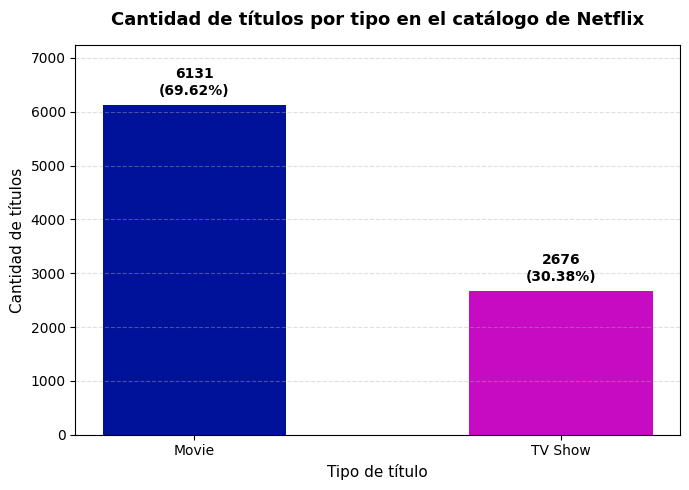

In [0]:
import matplotlib.pyplot as plt

df_tipos = (
    analisis_a_pyspark
    .orderBy(F.col("cantidad_titulos").desc(), F.col("tipo").asc())
    .toPandas()
)

total_clasificados = df_tipos["cantidad_titulos"].sum()
df_tipos["porcentaje"] = (df_tipos["cantidad_titulos"] / total_clasificados) * 100

fig, ax = plt.subplots(figsize=(7, 5))
barras = ax.bar(df_tipos["tipo"], df_tipos["cantidad_titulos"], color=["#00129A", "#C70BC3"], width=0.5)

for barra, (_, fila) in zip(barras, df_tipos.iterrows()):
    altura = barra.get_height()
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        altura + (total_clasificados * 0.015),
        f"{int(fila['cantidad_titulos'])}\n({fila['porcentaje']:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax.set_xlabel("Tipo de título", fontsize=11)
ax.set_ylabel("Cantidad de títulos", fontsize=11)
ax.set_ylim(0, df_tipos["cantidad_titulos"].max() * 1.18)
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

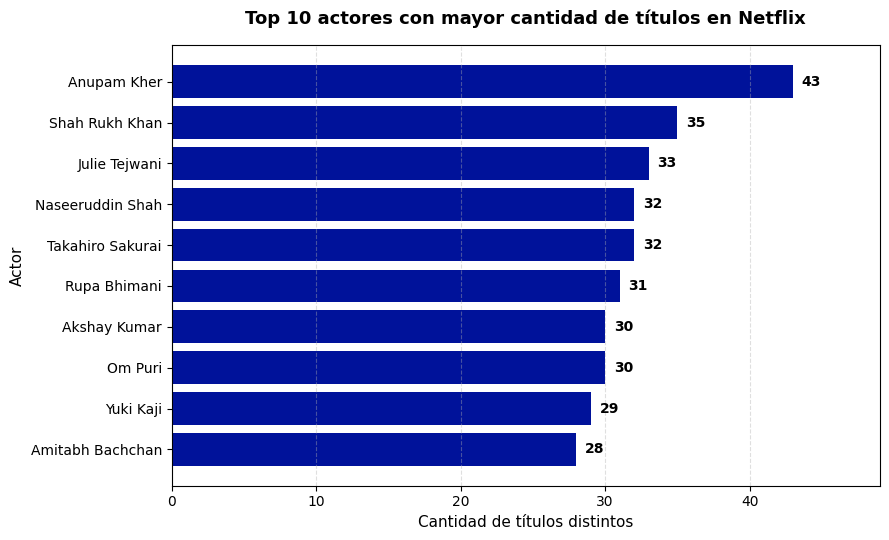

In [0]:
df_top_actores = (
    actores_pyspark
    .orderBy(F.col("cantidad_titulos").desc(), F.col("actor").asc())
    .limit(10)
    .toPandas()
)

# Invertir orden para que el mayor quede arriba en barras horizontales
df_top_actores = df_top_actores.iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 5.5))
barras = ax.barh(df_top_actores["actor"], df_top_actores["cantidad_titulos"], color="#00129A")

for barra in barras:
    ancho = barra.get_width()
    ax.text(
        ancho + 0.6,
        barra.get_y() + barra.get_height() / 2,
        f"{int(ancho)}",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold"
    )

ax.set_xlabel("Cantidad de títulos distintos", fontsize=11)
ax.set_ylabel("Actor", fontsize=11)
ax.set_xlim(0, df_top_actores["cantidad_titulos"].max() * 1.14)
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

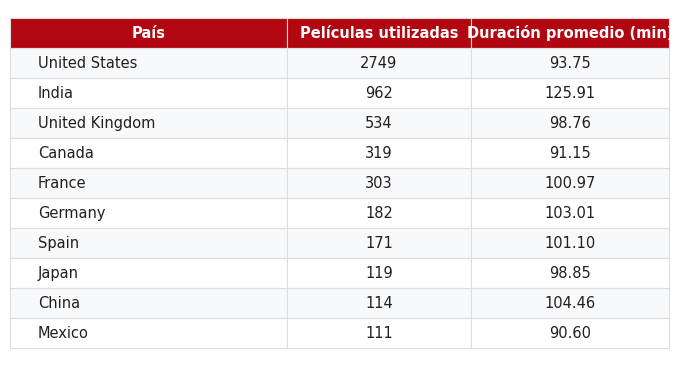

---------------------------------------------------------------------------
TypeError                                 Traceback (most recent call last)
File <command-4564162797572937>, line 42
     39         if col == 0:
     40             celda.get_text().set_ha("left")
---> 42 ax.set_title(
     43     fontsize=12.5,
     44     fontweight="bold",
     45     color="#221F1F",
     46     pad=12
     47 )
     49 plt.tight_layout()
     50 plt.show()

TypeError: Axes.set_title() missing 1 required positional argument: 'label'

In [0]:
import matplotlib.pyplot as plt

df_tabla_6 = (
    analisis_c_pyspark
    .orderBy(F.col("cantidad_peliculas").desc(), F.col("pais").asc())
    .limit(10)
    .select(
        F.col("pais").alias("País"),
        F.col("cantidad_peliculas").alias("Películas utilizadas"),
        F.format_number(F.col("duracion_promedio_min"), 2).alias("Duración promedio (min)")
    )
    .toPandas()
)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.axis("off")

tabla = ax.table(
    cellText=df_tabla_6.values,
    colLabels=df_tabla_6.columns,
    cellLoc="center",
    loc="center",
    colWidths=[0.42, 0.28, 0.30]
)

tabla.auto_set_font_size(False)
tabla.set_fontsize(10.5)
tabla.scale(1, 1.8)

for (fila, col), celda in tabla.get_celld().items():
    celda.set_edgecolor("#DDDDDD")
    celda.set_linewidth(0.8)
    if fila == 0:
        celda.set_facecolor("#B20710")
        celda.set_text_props(color="white", fontweight="bold")
    else:
        celda.set_facecolor("#F8F9FA" if fila % 2 == 1 else "#FFFFFF")
        celda.set_text_props(color="#221F1F")
        if col == 0:
            celda.get_text().set_ha("left")

ax.set_title(
    fontsize=12.5,
    fontweight="bold",
    color="#221F1F",
    pad=12
)

plt.tight_layout()
plt.show()